# Variance envelopes (Figure 2)

Pointwise variance envelope $V_h(R)$ for the squared exponential, rational
quadratic and Matérn profiles, with the radii at which its second and third
terms become active.

Output: `figs/variance_envelope.{pdf,png}`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

from bigf import bounds, profiles
from bigf.paths import relative
from bigf.plotting import SERIF_STYLE, save_figure

ELL = 1.0
RADII = ELL * np.geomspace(0.01, 4.0, 1600)
Y_LIMITS = (1e-3, 2e4)

PROFILES = list(profiles.manuscript_profiles(ELL).values())

print(f"{len(PROFILES)} profiles, {RADII.size} radii, R/ell in "
      f"[{RADII[0] / ELL:g}, {RADII[-1] / ELL:g}].")

5 profiles, 1600 radii, R/ell in [0.01, 4].


## Envelopes and activation radii

In [2]:
ENVELOPES = {}
ACTIVATION_RADII = {}

print(f"{'Profile':<22} {'B: R/ell':>10} {'C: R/ell':>10}")
for profile in PROFILES:
    r_b, r_c = bounds.activation_radii(profile)
    ENVELOPES[profile.name] = bounds.variance_envelope(profile, RADII)
    ACTIVATION_RADII[profile.name] = (r_b, r_c)
    print(f"{profile.name:<22} {r_b / profile.ell:10.6f} {r_c / profile.ell:10.6f}")

Profile                  B: R/ell   C: R/ell
squared_exponential      0.588705   0.588705
rational_quadratic       0.455090   0.360500
matern_5_2               0.484497   0.200094
matern_7_2               0.521061   0.375290
matern_9_2               0.538518   0.440377


## Figures

In [3]:
REGIME_COLORS = ("#E8F2F9", "#FFF3D4", "#F0F0F0")
REGIME_LABELS = ("Local envelope", "Transition", "Far envelope")


def draw_envelope(ax, profile, panel):
    """Plot V_h(R) for one profile, with its three regimes shaded."""
    x = RADII / ELL
    low, high = sorted(r / profile.ell for r in ACTIVATION_RADII[profile.name])
    zones = (
        (x[0], low, REGIME_COLORS[0]),
        (low, high, REGIME_COLORS[1]),
        (high, x[-1], REGIME_COLORS[2]),
    )
    for left, right, color in zones:
        left, right = max(left, x[0]), min(right, x[-1])
        if right - left > 1e-10:
            ax.axvspan(left, right, facecolor=color, edgecolor="none", zorder=0)

    ax.plot(x, ENVELOPES[profile.name], color="#181818", linewidth=1.9, zorder=3)
    for root in sorted({round(low, 12), round(high, 12)}):
        ax.axvline(root, color="#777777", linestyle=(0, (2.5, 2.5)),
                   linewidth=0.7, zorder=2)

    ax.set_title(f"({chr(97 + panel)}) {profile.label}", pad=8)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(x[0], x[-1])
    ax.set_ylim(*Y_LIMITS)
    ax.set_xticks([0.01, 0.1, 1.0, 4.0])
    ax.set_xticklabels([r"$10^{-2}$", r"$10^{-1}$", r"$1$", r"$4$"])
    ax.set_yticks([1e-3, 1e-1, 1e1, 1e3])
    ax.grid(True, which="major", color="#A5A5A5", alpha=0.32, linewidth=0.45)
    ax.tick_params(which="major", direction="out", width=0.65, length=3.0)
    ax.tick_params(which="minor", direction="out", width=0.4, length=1.8)


def make_envelope_figure(rows, stem):
    """Plot one envelope per panel, one row of panels per entry of rows.

    Panels are lettered row by row. Unused cells are left blank, and the
    legend goes in the first of them. The figure is saved as PDF and PNG.
    """
    n_cols = max(len(row) for row in rows)

    with plt.rc_context({**SERIF_STYLE, "legend.fontsize": 9}):
        fig, axes = plt.subplots(
            len(rows), n_cols, figsize=(6.85, 5.0),
            sharex=True, sharey=True, squeeze=False
        )
        fig.subplots_adjust(
            left=0.105, right=0.985, bottom=0.11, top=0.94,
            wspace=0.13, hspace=0.34
        )

        panel = 0
        unused = []
        for i, row in enumerate(rows):
            for j in range(n_cols):
                if j < len(row):
                    draw_envelope(axes[i, j], row[j], panel)
                    axes[i, j].label_outer()
                    panel += 1
                else:
                    axes[i, j].set_axis_off()
                    unused.append(axes[i, j])

        fig.text(0.545, 0.03, r"Normalized radius $R/\ell$",
                 ha="center", va="center", fontsize=10)
        fig.text(0.021, 0.52, r"Variance envelope $V_h(R)$", rotation=90,
                 ha="center", va="center", fontsize=10)

        handles = [
            Patch(facecolor=color, edgecolor="#BBBBBB", linewidth=0.4, label=label)
            for color, label in zip(REGIME_COLORS, REGIME_LABELS)
        ]
        legend_kwargs = dict(handles=handles, frameon=False, handlelength=1.6,
                             handletextpad=0.55)
        if unused:
            unused[0].legend(loc="center", **legend_kwargs)
        else:
            fig.legend(loc="upper center", ncol=3, **legend_kwargs)

        paths = save_figure(
            fig, stem, dpi=300,
            metadata={
                "Title": "Pointwise variance envelope: " + ", ".join(
                    profile.name for row in rows for profile in row
                ),
                "Creator": "01_variance_envelopes.ipynb",
            },
        )
        plt.show()
        plt.close(fig)

    return paths

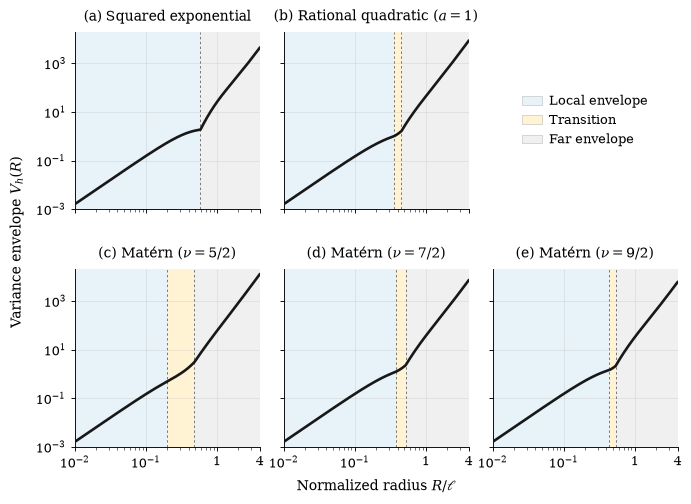

Saved: figs/variance_envelope.pdf
Saved: figs/variance_envelope.png


In [4]:
# First row: squared exponential and rational quadratic. Second row: Matérn.
envelope_pdf, envelope_png = make_envelope_figure(
    (PROFILES[:2], PROFILES[2:]), "variance_envelope"
)

print(f"Saved: {relative(envelope_pdf)}\nSaved: {relative(envelope_png)}")